In [1]:
import pandas as pd
from pathlib import Path


AUTHENTIC_ROOT = Path("dataset_split/train/authentic")
FORENSIC_ROOT = Path("dataset_split/train/forged")

material_classes = {
    "Biological",
    "Fibres",
    "Nanowires",
    "Particles",
    "Porous_Sponge",
    "Powder"
}

device_classes = {
    "Films_Coated_Surface",
    "MEMS_devices_and_electrodes",
    "Patterned_surface",
    "Tips"
}


records = []

# -----------------------------------
# Add Authentic Images
# -----------------------------------

for class_dir in AUTHENTIC_ROOT.iterdir():

    if not class_dir.is_dir():
        continue

    defect_type = class_dir.name

    if defect_type in material_classes:
        domain = "Material"
    else:
        domain = "Device"

    for img_path in class_dir.glob("*"):

        records.append({

            "image_name":
                img_path.name,

            "image_path":
                str(img_path),

            "defect_type":
                defect_type,

            "domain":
                domain,

            "authenticity":
                "Authentic",

            "mask_path":
                ""

        })


# -----------------------------------
# Add Forged Images
# -----------------------------------

for forgery_type_dir in FORENSIC_ROOT.iterdir():

    if not forgery_type_dir.is_dir():
        continue

    forgery_type = forgery_type_dir.name

    for class_dir in forgery_type_dir.iterdir():

        if not class_dir.is_dir():
            continue

        defect_type = class_dir.name

        domain = (
            "Material"
            if defect_type in material_classes
            else "Device"
        )

        for img_path in class_dir.glob("*"):

            mask_path = str(

                Path(
                    "dataset_split/train/masks"
                )

                / forgery_type
                / defect_type
                / img_path.name
            )

            records.append({

                "image_name":
                    img_path.name,

                "image_path":
                    str(img_path),

                "defect_type":
                    defect_type,

                "domain":
                    domain,

                "authenticity":
                    forgery_type,

                "mask_path":
                    mask_path
            })
# -----------------------------------
# Create DataFrame
# -----------------------------------

df = pd.DataFrame(records)

print(df.head())

# -----------------------------------
# Save CSV
# -----------------------------------

df.to_csv(
    "SEM_forensic_metadata.csv",
    index=False
)

print(
    f"\nTotal records: {len(df)}"
)

print(
    "\nSaved as SEM_forensic_metadata.csv"
)

                                image_name  \
0  L4_c0881a70509cbc98a7e8eff93d86f2f9.jpg   
1  L4_29ad5d70767fc5a51b0ce4f232fae40e.jpg   
2  L4_80ed47ecd9b707cf5210fd548f7c7286.jpg   
3  L4_a32d5b70c1374299f1866f966f3c081a.jpg   
4  L4_b3e693c0c3ab2d746d6600bcd8981c44.jpg   

                                          image_path defect_type    domain  \
0  dataset_split/train/authentic/Powder/L4_c0881a...      Powder  Material   
1  dataset_split/train/authentic/Powder/L4_29ad5d...      Powder  Material   
2  dataset_split/train/authentic/Powder/L4_80ed47...      Powder  Material   
3  dataset_split/train/authentic/Powder/L4_a32d5b...      Powder  Material   
4  dataset_split/train/authentic/Powder/L4_b3e693...      Powder  Material   

  authenticity mask_path  
0    Authentic            
1    Authentic            
2    Authentic            
3    Authentic            
4    Authentic            

Total records: 3600

Saved as SEM_forensic_metadata.csv


In [2]:
#pip install torch torchvision timm opencv-python scikit-image pillow

In [3]:
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from PIL import Image
from skimage.feature import local_binary_pattern

import timm

from torchvision.models import efficientnet_b0

import pandas as pd

import torch
from torch.utils.data import Dataset
from torchvision import transforms
from torch.utils.data import DataLoader

In [4]:
from io import BytesIO
class ForensicPreprocessor:

    def __init__(self,
                 lbp_radius=2,
                 lbp_points=16):

        self.radius = lbp_radius
        self.points = lbp_points

    def normalize(self, img):

        img = img.astype(np.float32)
    
        min_val = img.min()
        max_val = img.max()
    
        if max_val - min_val < 1e-8:
            return np.zeros_like(img, dtype=np.float32)
    
        return (
            img - min_val
        ) / (
            max_val - min_val
        )

    def residual_map(self, img):

        blur = cv2.GaussianBlur(
            img,
            (5,5),
            0
        )

        residual = cv2.absdiff(
            img,
            blur
        )

        return self.normalize(residual)

    def fft_map(self, img):

        f = np.fft.fft2(img)

        fshift = np.fft.fftshift(f)

        magnitude = np.log(
            np.abs(fshift)+1
        )

        return self.normalize(magnitude)

    def lbp_map(self, img):

        lbp = local_binary_pattern(
            img,
            P=self.points,
            R=self.radius,
            method='uniform'
        )

        return self.normalize(lbp)

    def ela_map(self, img):
    
        buffer = BytesIO()
    
        Image.fromarray(img).save(
            buffer,
            format="JPEG",
            quality=90
        )
    
        buffer.seek(0)
    
        recompressed = np.array(
            Image.open(buffer).convert("L")
        )
    
        ela = cv2.absdiff(
            img,
            recompressed
        )
    
        return self.normalize(ela)

    def process(self, img):

        residual = self.residual_map(img)

        fft = self.fft_map(img)

        lbp = self.lbp_map(img)

        ela = self.ela_map(img)

        stacked = np.stack([
            residual,
            fft,
            lbp,
            ela
        ], axis=0)

        return stacked

In [5]:
class CNNBranch(nn.Module):

    def __init__(self):

        super().__init__()

        backbone = efficientnet_b0(
            weights="DEFAULT"
        )

        backbone.classifier = nn.Identity()

        self.backbone = backbone

    def forward(self,x):

        return self.backbone(x)

In [6]:
import torch.nn.functional as F

class ViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.vit = timm.create_model(
            'vit_base_patch16_224',
            pretrained=True,
            num_classes=0
        )

    def forward(self, x):

        x = F.interpolate(
            x,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        return self.vit(x)

In [7]:
class MorphologyBranch(nn.Module):

    def __init__(self):

        super().__init__()

        self.cnn = CNNBranch()

        self.vit = ViTBranch()

        self.fc = nn.Sequential(

            nn.Linear(
                1280+768,
                1024
            ),

            nn.ReLU(),

            nn.Dropout(0.3)
        )

    def forward(self,x):

        cnn_feat = self.cnn(x)

        vit_feat = self.vit(x)

        combined = torch.cat(
            [
                cnn_feat,
                vit_feat
            ],
            dim=1
        )

        morphology_feat = self.fc(
            combined
        )

        return morphology_feat

In [8]:
class ForensicCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                4,
                32,
                3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                3,
                padding=1
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.fc = nn.Linear(
            128,
            256
        )

    def forward(self,x):

        x = self.features(x)

        x = x.view(
            x.size(0),
            -1
        )

        x = self.fc(x)

        return x

In [9]:
class FeatureFusion(nn.Module):

    def __init__(self):
        super().__init__()

        self.morph_proj = nn.Sequential(
            nn.Linear(1024, 512),
            nn.LayerNorm(512),
            nn.ReLU()
        )

        self.forensic_proj = nn.Sequential(
            nn.Linear(256, 512),
            nn.LayerNorm(512),
            nn.ReLU()
        )

        self.gate = nn.Sequential(
            nn.Linear(1024, 512),
            nn.Sigmoid()
        )

        self.output_fc = nn.Sequential(
            nn.Linear(512, 512),
            nn.LayerNorm(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

    def forward(
        self,
        morphology_feat,
        forensic_feat
    ):

        morphology_feat = self.morph_proj(
            morphology_feat
        )

        forensic_feat = self.forensic_proj(
            forensic_feat
        )

        combined = torch.cat(
            [
                morphology_feat,
                forensic_feat
            ],
            dim=1
        )

        gate = self.gate(combined)

        fused = (
            gate * morphology_feat
            +
            (1.0 - gate) * forensic_feat
        )

        fused = self.output_fc(fused)

        return fused

In [10]:
class SEMFeatureExtractor(nn.Module):

    def __init__(self):

        super().__init__()

        self.morphology = MorphologyBranch()

        self.forensic = ForensicCNN()

        self.fusion = FeatureFusion()

    def forward(
        self,
        sem_image,
        forensic_maps
    ):

        morphology_feat = self.morphology(
            sem_image
        )

        forensic_feat = self.forensic(
            forensic_maps
        )

        fused_feat = self.fusion(
            morphology_feat,
            forensic_feat
        )

        return {

            "morphology_features":
                morphology_feat,

            "forensic_features":
                forensic_feat,

            "fused_features":
                fused_feat
        }

In [11]:
DEFECT_MAP = {
    "Biological":0,
    "Fibres":1,
    "Films_Coated_Surface":2,
    "MEMS_devices_and_electrodes":3,
    "Nanowires":4,
    "Particles":5,
    "Patterned_surface":6,
    "Porous_Sponge":7,
    "Powder":8,
    "Tips":9
}

DOMAIN_MAP = {
    "Material":0,
    "Device":1
}

AUTH_MAP = {
    "Authentic":0,
    "copy_move":1,
    "splicing":2,
    "synthetic":3,
    "contrast":4
}

In [12]:
class SEMForensicDataset(Dataset):

    def __init__(
        self,
        csv_file,
        forensic_preprocessor
        # forensic_preprocessor,
        # image_size=224
    ):

        self.df = pd.read_csv(csv_file)

        self.preprocessor = forensic_preprocessor

        self.transform = transforms.Compose([

            transforms.ToPILImage(),

            # transforms.Resize(
            #     (image_size,image_size)
            # ),

            transforms.Grayscale(
                num_output_channels=3
            ),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        img_path = row["image_path"]

        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )

        # img_resized = cv2.resize(
        #     img,
        #     (224,224)
        # )

        sem_tensor = self.transform(
            #img_resized
            img
        )

        forensic_maps = self.preprocessor.process(
            #img_resized
            img
        )

        forensic_tensor = torch.tensor(
            forensic_maps,
            dtype=torch.float32
        )

        defect_label = DEFECT_MAP[
            row["defect_type"]
        ]

        domain_label = DOMAIN_MAP[
            row["domain"]
        ]

        auth_label = AUTH_MAP[
            row["authenticity"]
        ]

        sample = {

            "sem_image":
                sem_tensor,

            "forensic_maps":
                forensic_tensor,

            "defect":
                torch.tensor(
                    defect_label
                ),

            "domain":
                torch.tensor(
                    domain_label
                ),

            "auth":
                torch.tensor(
                    auth_label
                )
        }

        return sample

In [13]:
preprocessor = ForensicPreprocessor()

dataset = SEMForensicDataset(

    csv_file=
    "SEM_forensic_metadata.csv",

    forensic_preprocessor=
    preprocessor
)

In [14]:
train_loader = DataLoader(

    dataset,

    batch_size=16,

    shuffle=True,

    num_workers=0
)

In [15]:
class MultiTaskClassifier(nn.Module):

    def __init__(self,
                 input_dim=512):

        super().__init__()

        # Shared representation

        self.shared = nn.Sequential(

            nn.Linear(input_dim, 256),

            nn.BatchNorm1d(256),

            nn.ReLU(),

            nn.Dropout(0.3)
        )

        # -----------------------
        # Defect Head
        # -----------------------

        self.defect_head = nn.Sequential(

            nn.Linear(256,128),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(128,10)
        )

        # -----------------------
        # Domain Head
        # -----------------------

        self.domain_head = nn.Sequential(

            nn.Linear(256,64),

            nn.ReLU(),

            nn.Linear(64,2)
        )

        # -----------------------
        # Authenticity Head
        # -----------------------

        self.auth_head = nn.Sequential(

            nn.Linear(256,128),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(128,5)
        )

    def forward(self,x):

        shared_feat = self.shared(x)

        defect_logits = self.defect_head(
            shared_feat
        )

        domain_logits = self.domain_head(
            shared_feat
        )

        auth_logits = self.auth_head(
            shared_feat
        )

        return {

            "defect_logits":
                defect_logits,

            "domain_logits":
                domain_logits,

            "auth_logits":
                auth_logits
        }

In [16]:
class ForensicSEMModel(nn.Module):

    def __init__(self,
                 feature_extractor):

        super().__init__()

        self.feature_extractor = feature_extractor

        self.classifier = MultiTaskClassifier()

    def forward(
        self,
        sem_image,
        forensic_maps
    ):

        features = self.feature_extractor(
            sem_image,
            forensic_maps
        )
    
        fused_features = features[
            "fused_features"
        ]
    
        outputs = self.classifier(
            fused_features
        )
    
        return outputs

In [17]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

feature_extractor = SEMFeatureExtractor()

model = ForensicSEMModel(
    feature_extractor
).to(device)

In [18]:
from sklearn.utils.class_weight import compute_class_weight

train_defect_labels = []
train_domain_labels = []
train_auth_labels = []

for batch in train_loader:

    train_defect_labels.extend(
        batch["defect"].cpu().numpy()
    )

    train_domain_labels.extend(
        batch["domain"].cpu().numpy()
    )

    train_auth_labels.extend(
        batch["auth"].cpu().numpy()
    )

train_defect_labels = np.array(train_defect_labels)
train_domain_labels = np.array(train_domain_labels)
train_auth_labels = np.array(train_auth_labels)

defect_classes = np.unique(train_defect_labels)

defect_weights = compute_class_weight(
    class_weight="balanced",
    classes=defect_classes,
    y=train_defect_labels
)

defect_weights = torch.tensor(
    defect_weights,
    dtype=torch.float32
).to(device)

domain_classes = np.unique(train_domain_labels)

domain_weights = compute_class_weight(
    class_weight="balanced",
    classes=domain_classes,
    y=train_domain_labels
)

domain_weights = torch.tensor(
    domain_weights,
    dtype=torch.float32
).to(device)

auth_classes = np.unique(train_auth_labels)

auth_weights = compute_class_weight(
    class_weight="balanced",
    classes=auth_classes,
    y=train_auth_labels
)

auth_weights = torch.tensor(
    auth_weights,
    dtype=torch.float32
).to(device)

In [19]:
from sklearn.utils.class_weight import compute_class_weight

def compute_loss(
    outputs,
    defect_labels,
    domain_labels,
    auth_labels
):
       
    #defect_loss_fn = nn.CrossEntropyLoss(weight=defect_weights)
    defect_loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)

    loss_defect = defect_loss_fn(
        outputs["defect_logits"],
        defect_labels
    )
       
    #domain_loss_fn = nn.CrossEntropyLoss(weight=domain_weights)
    domain_loss_fn = nn.CrossEntropyLoss()
 
    loss_domain = domain_loss_fn(
        outputs["domain_logits"],
        domain_labels
    )

    auth_loss_fn = nn.CrossEntropyLoss(weight=auth_weights)

    loss_auth = auth_loss_fn(
        outputs["auth_logits"],
        auth_labels
    )

    total_loss = (

          loss_defect

        + loss_domain

        + loss_auth
    )

    return total_loss

In [20]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=50,
    eta_min=1e-6
)

In [21]:
num_epochs = 50

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for batch in train_loader:

        sem_images = batch["sem_image"].to(device)
        forensic_maps = batch["forensic_maps"].to(device)

        defect_labels = batch["defect"].long().to(device)
        domain_labels = batch["domain"].long().to(device)
        auth_labels = batch["auth"].long().to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            sem_images,
            forensic_maps
        )

        loss = compute_loss(
            outputs,
            defect_labels,
            domain_labels,
            auth_labels
        )

        loss.backward()

        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

       
        optimizer.step()

        running_loss += loss.item()

    
    scheduler.step()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {average_loss:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.7f}"
    )

Epoch [1/50] Loss: 4.0708 LR: 0.0002997
Epoch [2/50] Loss: 3.0743 LR: 0.0002988
Epoch [3/50] Loss: 2.5760 LR: 0.0002974
Epoch [4/50] Loss: 2.1166 LR: 0.0002953
Epoch [5/50] Loss: 1.7924 LR: 0.0002927
Epoch [6/50] Loss: 1.5156 LR: 0.0002895
Epoch [7/50] Loss: 1.3304 LR: 0.0002858
Epoch [8/50] Loss: 1.2172 LR: 0.0002815
Epoch [9/50] Loss: 1.0933 LR: 0.0002767
Epoch [10/50] Loss: 1.0418 LR: 0.0002714
Epoch [11/50] Loss: 0.9598 LR: 0.0002657
Epoch [12/50] Loss: 0.9282 LR: 0.0002595
Epoch [13/50] Loss: 0.8646 LR: 0.0002528
Epoch [14/50] Loss: 0.8613 LR: 0.0002458
Epoch [15/50] Loss: 0.8522 LR: 0.0002384
Epoch [16/50] Loss: 0.8365 LR: 0.0002306
Epoch [17/50] Loss: 0.8074 LR: 0.0002225
Epoch [18/50] Loss: 0.7568 LR: 0.0002142
Epoch [19/50] Loss: 0.7206 LR: 0.0002055
Epoch [20/50] Loss: 0.7130 LR: 0.0001967
Epoch [21/50] Loss: 0.6892 LR: 0.0001877
Epoch [22/50] Loss: 0.6626 LR: 0.0001785
Epoch [23/50] Loss: 0.6101 LR: 0.0001692
Epoch [24/50] Loss: 0.6180 LR: 0.0001599
Epoch [25/50] Loss: 0.569

In [22]:
AUTHENTIC_ROOT = Path("dataset_split/test/authentic")
FORENSIC_ROOT = Path("dataset_split/test/forged")

material_classes = {
    "Biological",
    "Fibres",
    "Nanowires",
    "Particles",
    "Porous_Sponge",
    "Powder"
}

device_classes = {
    "Films_Coated_Surface",
    "MEMS_devices_and_electrodes",
    "Patterned_surface",
    "Tips"
}


records = []

# -----------------------------------
# Add Authentic Images
# -----------------------------------

for class_dir in AUTHENTIC_ROOT.iterdir():

    if not class_dir.is_dir():
        continue

    defect_type = class_dir.name

    if defect_type in material_classes:
        domain = "Material"
    else:
        domain = "Device"

    for img_path in class_dir.glob("*"):

        records.append({

            "image_name":
                img_path.name,

            "image_path":
                str(img_path),

            "defect_type":
                defect_type,

            "domain":
                domain,

            "authenticity":
                "Authentic",

            "mask_path":
                ""

        })


# -----------------------------------
# Add Forged Images
# -----------------------------------

for forgery_type_dir in FORENSIC_ROOT.iterdir():

    if not forgery_type_dir.is_dir():
        continue

    forgery_type = forgery_type_dir.name

    for class_dir in forgery_type_dir.iterdir():

        if not class_dir.is_dir():
            continue

        defect_type = class_dir.name

        domain = (
            "Material"
            if defect_type in material_classes
            else "Device"
        )

        for img_path in class_dir.glob("*"):

            mask_path = str(

                Path(
                    "dataset_split/test/masks"
                )

                / forgery_type
                / defect_type
                / img_path.name
            )

            records.append({

                "image_name":
                    img_path.name,

                "image_path":
                    str(img_path),

                "defect_type":
                    defect_type,

                "domain":
                    domain,

                "authenticity":
                    forgery_type,

                "mask_path":
                    mask_path
            })
# -----------------------------------
# Create DataFrame
# -----------------------------------

df = pd.DataFrame(records)

print(df.head())

# -----------------------------------
# Save CSV
# -----------------------------------

df.to_csv(
    "SEM_forensic_metadata_test.csv",
    index=False
)

print(
    f"\nTotal records: {len(df)}"
)

print(
    "\nSaved as SEM_forensic_metadata.csv"
)

                                image_name  \
0  L4_31f600bbeaedd8e5864d0bdb7ae90b1a.jpg   
1  L4_87b7aae0859a54360b0ba7d96cf1a6a0.jpg   
2  L4_abcdfcc55a588be31b4d95b317820250.jpg   
3  L4_3e2bcd1e9d82cca5b97116aa46adbde2.jpg   
4  L4_1bba0cf4a9f6e655e71b4430ca0ee22d.jpg   

                                          image_path defect_type    domain  \
0  dataset_split/test/authentic/Powder/L4_31f600b...      Powder  Material   
1  dataset_split/test/authentic/Powder/L4_87b7aae...      Powder  Material   
2  dataset_split/test/authentic/Powder/L4_abcdfcc...      Powder  Material   
3  dataset_split/test/authentic/Powder/L4_3e2bcd1...      Powder  Material   
4  dataset_split/test/authentic/Powder/L4_1bba0cf...      Powder  Material   

  authenticity mask_path  
0    Authentic            
1    Authentic            
2    Authentic            
3    Authentic            
4    Authentic            

Total records: 900

Saved as SEM_forensic_metadata.csv


In [23]:
preprocessor = ForensicPreprocessor()

test_dataset = SEMForensicDataset(

    csv_file=
    "SEM_forensic_metadata_test.csv",

    forensic_preprocessor=
    preprocessor
)

In [24]:
test_loader = DataLoader(

    test_dataset,

    batch_size=16,

    shuffle=False,

    num_workers=0
)

In [25]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

In [26]:
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)


# ============================================================
# CLASS NAMES
# ============================================================

DEFECT_NAMES = {
    0: "Biological",
    1: "Fibres",
    2: "Films_Coated_Surface",
    3: "MEMS_devices_and_electrodes",
    4: "Nanowires",
    5: "Particles",
    6: "Patterned_surface",
    7: "Porous_Sponge",
    8: "Powder",
    9: "Tips"
}


DOMAIN_NAMES = {
    0: "Material",
    1: "Device"
}


AUTH_NAMES = {
    0: "Authentic",
    1: "copy_move",
    2: "splicing",
    3: "synthetic",
    4: "contrast"
}


# ============================================================
# EVALUATION + SAMPLE COLLECTION
# ============================================================

def evaluate_model(
        model,
        test_loader,
        device):

    model.eval()

    defect_true = []
    defect_pred = []
    defect_conf = []

    domain_true = []
    domain_pred = []
    domain_conf = []

    auth_true = []
    auth_pred = []
    auth_conf = []

    # --------------------------------------------------------
    # Store images for qualitative visualization
    # --------------------------------------------------------

    defect_samples = []
    domain_samples = []
    auth_samples = []


    # ========================================================
    # INFERENCE
    # ========================================================

    with torch.no_grad():

        for batch in test_loader:

            sem_images = batch[
                "sem_image"
            ].to(device)

            forensic_maps = batch[
                "forensic_maps"
            ].to(device)


            outputs = model(
                sem_images,
                forensic_maps
            )


            # =================================================
            # DEFECT
            # =================================================

            defect_probs = torch.softmax(
                outputs["defect_logits"],
                dim=1
            )

            defect_out = torch.argmax(
                defect_probs,
                dim=1
            )

            defect_probability = torch.max(
                defect_probs,
                dim=1
            ).values


            # =================================================
            # DOMAIN
            # =================================================

            domain_probs = torch.softmax(
                outputs["domain_logits"],
                dim=1
            )

            domain_out = torch.argmax(
                domain_probs,
                dim=1
            )

            domain_probability = torch.max(
                domain_probs,
                dim=1
            ).values


            # =================================================
            # AUTHENTICITY
            # =================================================

            auth_probs = torch.softmax(
                outputs["auth_logits"],
                dim=1
            )

            auth_out = torch.argmax(
                auth_probs,
                dim=1
            )

            auth_probability = torch.max(
                auth_probs,
                dim=1
            ).values


            # =================================================
            # PROCESS EACH IMAGE IN BATCH
            # =================================================

            batch_size = sem_images.size(0)

            for i in range(batch_size):

                # ------------------------------------------------
                # Keep image on CPU
                # ------------------------------------------------

                image = sem_images[i].detach().cpu()


                # ------------------------------------------------
                # DEFECT
                # ------------------------------------------------

                d_true = int(
                    batch["defect"][i].item()
                )

                d_pred = int(
                    defect_out[i].item()
                )

                d_conf = float(
                    defect_probability[i].item()
                )


                defect_true.append(d_true)
                defect_pred.append(d_pred)
                defect_conf.append(d_conf)


                defect_samples.append({

                    "image": image,

                    "true": d_true,

                    "pred": d_pred,

                    "confidence": d_conf
                })


                # ------------------------------------------------
                # DOMAIN
                # ------------------------------------------------

                dom_true = int(
                    batch["domain"][i].item()
                )

                dom_pred = int(
                    domain_out[i].item()
                )

                dom_conf = float(
                    domain_probability[i].item()
                )


                domain_true.append(dom_true)
                domain_pred.append(dom_pred)
                domain_conf.append(dom_conf)


                domain_samples.append({

                    "image": image,

                    "true": dom_true,

                    "pred": dom_pred,

                    "confidence": dom_conf
                })


                # ------------------------------------------------
                # AUTHENTICITY
                # ------------------------------------------------

                a_true = int(
                    batch["auth"][i].item()
                )

                a_pred = int(
                    auth_out[i].item()
                )

                a_conf = float(
                    auth_probability[i].item()
                )


                auth_true.append(a_true)
                auth_pred.append(a_pred)
                auth_conf.append(a_conf)


                auth_samples.append({

                    "image": image,

                    "true": a_true,

                    "pred": a_pred,

                    "confidence": a_conf
                })


    # ============================================================
    # RESULTS
    # ============================================================

    results = {}


    # ============================================================
    # DEFECT
    # ============================================================

    acc = accuracy_score(
        defect_true,
        defect_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            defect_true,
            defect_pred,
            average="weighted",
            zero_division=0
        )

    results["defect"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                defect_true,
                defect_pred
            )
    }


    # ============================================================
    # DOMAIN
    # ============================================================

    acc = accuracy_score(
        domain_true,
        domain_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            domain_true,
            domain_pred,
            average="weighted",
            zero_division=0
        )

    results["domain"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                domain_true,
                domain_pred
            )
    }


    # ============================================================
    # AUTHENTICITY
    # ============================================================

    acc = accuracy_score(
        auth_true,
        auth_pred
    )

    prec, rec, f1, _ = \
        precision_recall_fscore_support(
            auth_true,
            auth_pred,
            average="weighted",
            zero_division=0
        )

    results["auth"] = {

        "accuracy": acc,

        "precision": prec,

        "recall": rec,

        "f1": f1,

        "cm":
            confusion_matrix(
                auth_true,
                auth_pred
            )
    }


    # ============================================================
    # ADD QUALITATIVE SAMPLE DATA
    # ============================================================

    results["samples"] = {

        "defect": defect_samples,

        "domain": domain_samples,

        "auth": auth_samples
    }


    return results

In [27]:
import random
import matplotlib.pyplot as plt
import torch


def show_classification_examples(
    samples,
    class_names,
    task_name,
    n_correct=1,
    n_wrong=1,
    random_defect_wrong=False,
    seed=42
):
    random.seed(seed)

    print(f"\n{'='*80}")
    print(task_name)
    print(f"{'='*80}")

    for class_id, class_name in class_names.items():

        # ---------------------------------------------------------
        # Correctly classified samples
        # ---------------------------------------------------------
        correct = [
            x for x in samples
            if x["true"] == class_id and x["pred"] == class_id
        ]

        correct = correct[:n_correct]

        if correct:
            fig, ax = plt.subplots(figsize=(4, 4))

            sample = correct[0]
            image = sample["image"].clone()

            # Grayscale image
            if image.shape[0] == 1:
                image = image[0]
                ax.imshow(image, cmap="gray")

            # RGB image
            else:
                image = image.permute(1, 2, 0)
                ax.imshow(image)

            ax.set_title(
                f"GT: {class_name}\n"
                f"Pred: {class_name} "
                f"({sample['confidence']*100:.1f}%)"
            )
            ax.axis("off")

            plt.suptitle(
                f"{task_name} - Correct: {class_name}",
                fontsize=12
            )
            plt.tight_layout()
            plt.show()

        # ---------------------------------------------------------
        # Misclassified samples
        # ---------------------------------------------------------
        wrong = [
            x for x in samples
            if x["true"] == class_id and x["pred"] != class_id
        ]

        if random_defect_wrong:
            # Randomly select 3-4 misclassified samples
            n_random = min(random.choice([3, 4]), len(wrong))
            wrong = random.sample(wrong, n_random)
        else:
            # One misclassified sample
            wrong = wrong[:n_wrong]

        if wrong:

            fig, axes = plt.subplots(
                1,
                len(wrong),
                figsize=(4 * len(wrong), 4)
            )

            # Handle single image case
            if len(wrong) == 1:
                axes = [axes]

            for ax, sample in zip(axes, wrong):

                image = sample["image"].clone()

                if image.shape[0] == 1:
                    image = image[0]
                    ax.imshow(image, cmap="gray")
                else:
                    image = image.permute(1, 2, 0)
                    ax.imshow(image)

                pred_name = class_names[sample["pred"]]

                ax.set_title(
                    f"GT: {class_name}\n"
                    f"Pred: {pred_name}\n"
                    f"Confidence: {sample['confidence']*100:.1f}%"
                )

                ax.axis("off")

            plt.suptitle(
                f"{task_name} - Misclassified: {class_name}",
                fontsize=12
            )

            plt.tight_layout()
            plt.show()

In [29]:
results = evaluate_model(
    model=model,
    test_loader=test_loader,
    device=device
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).



Defect Classification


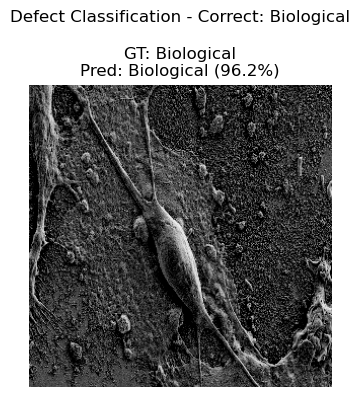

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


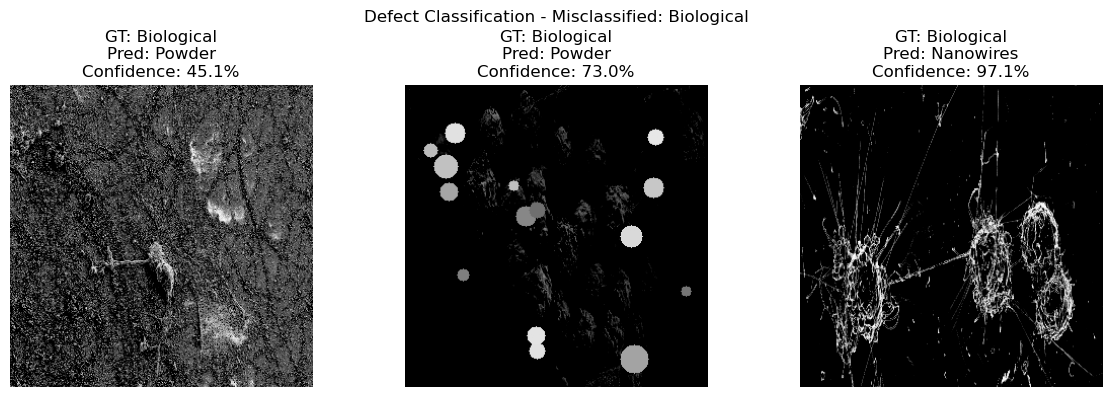

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


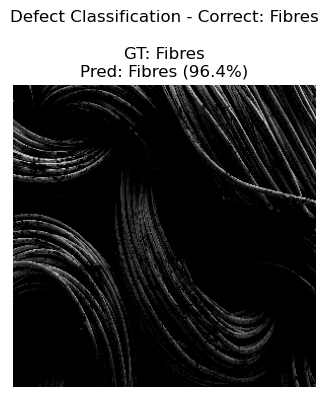

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


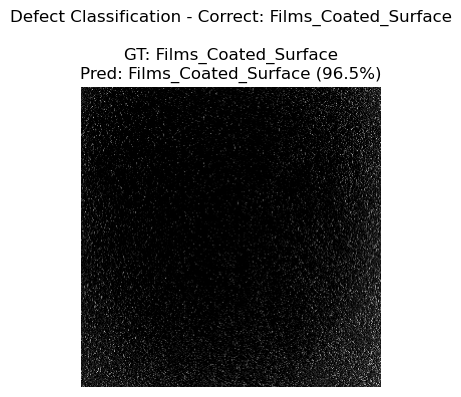

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


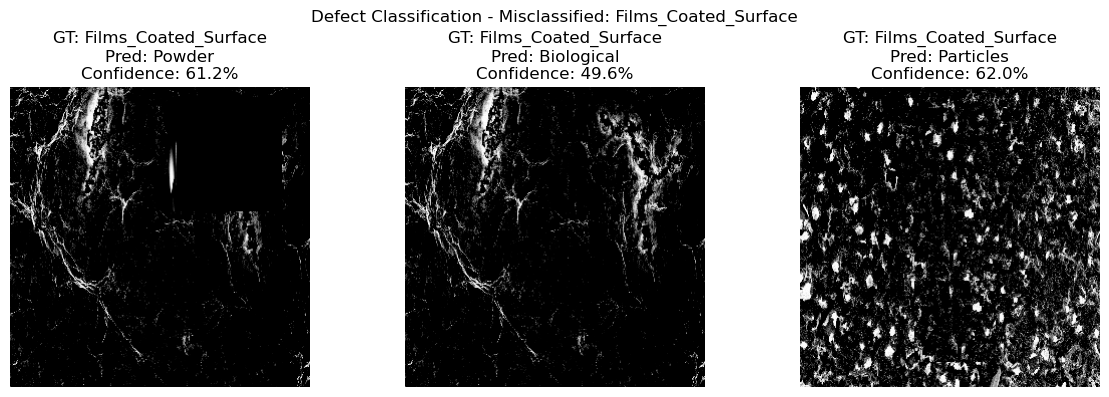

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


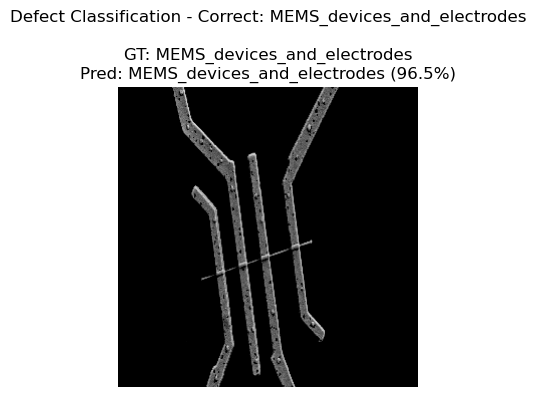

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


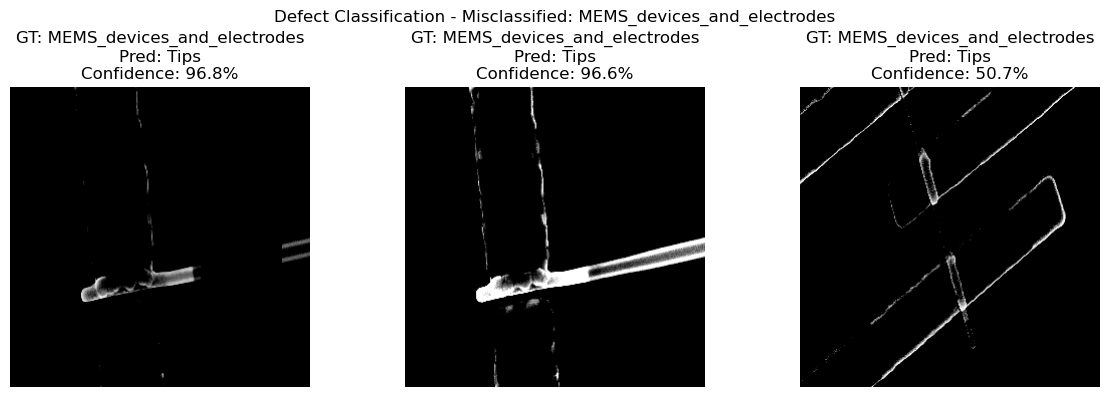

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


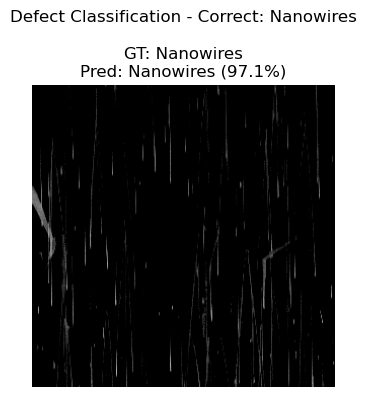

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


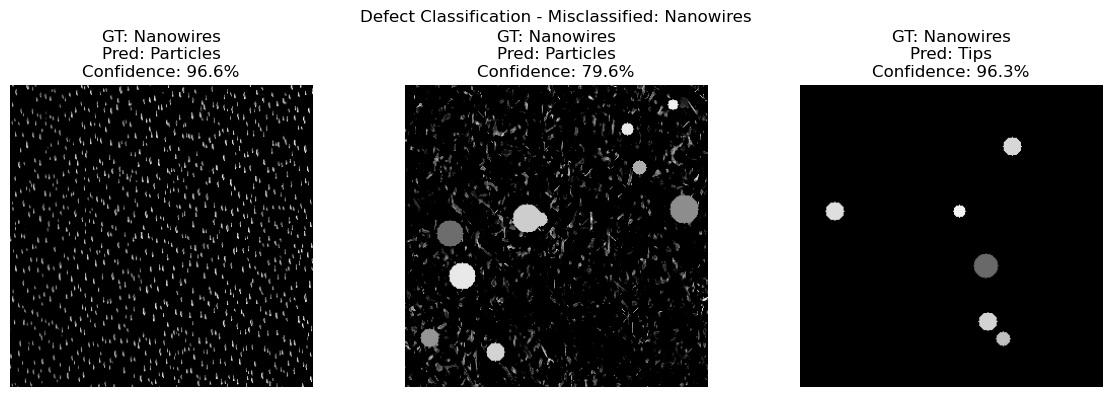

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


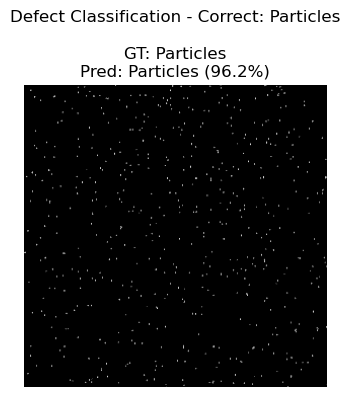

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


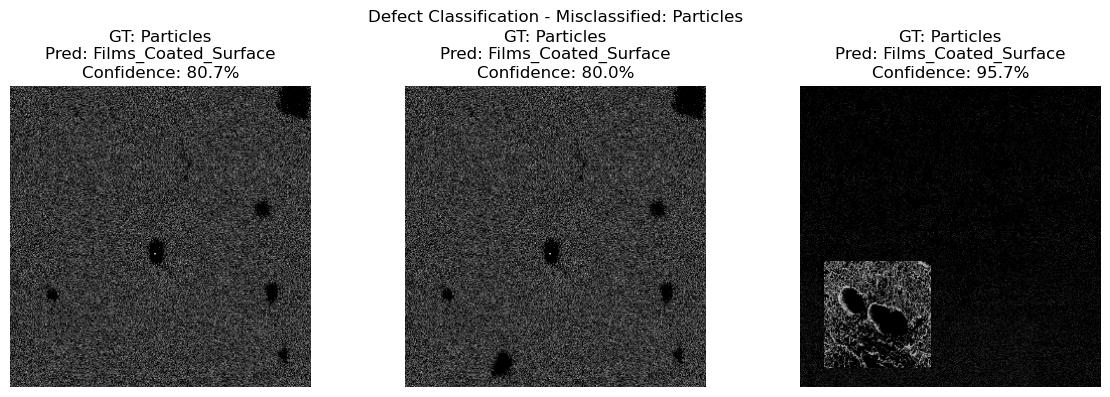

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


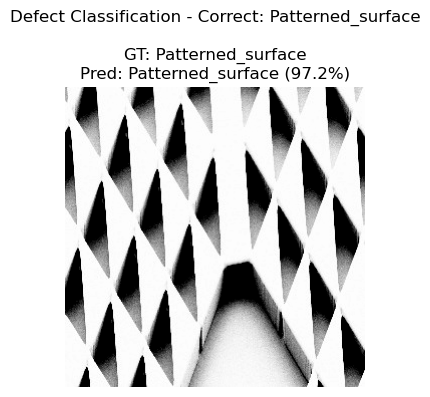

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


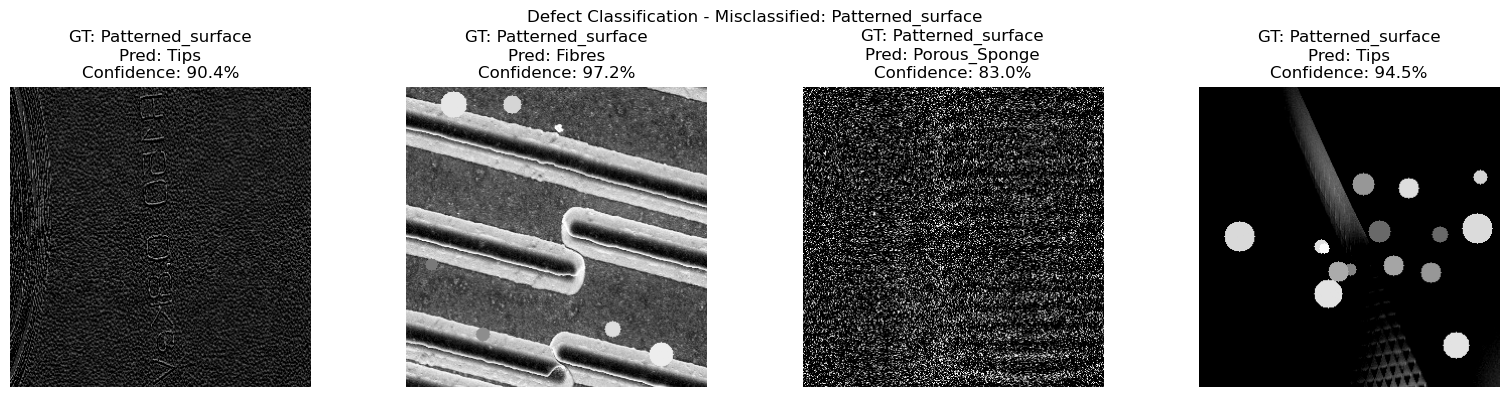

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


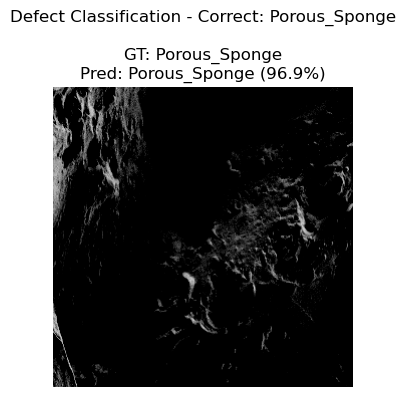

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


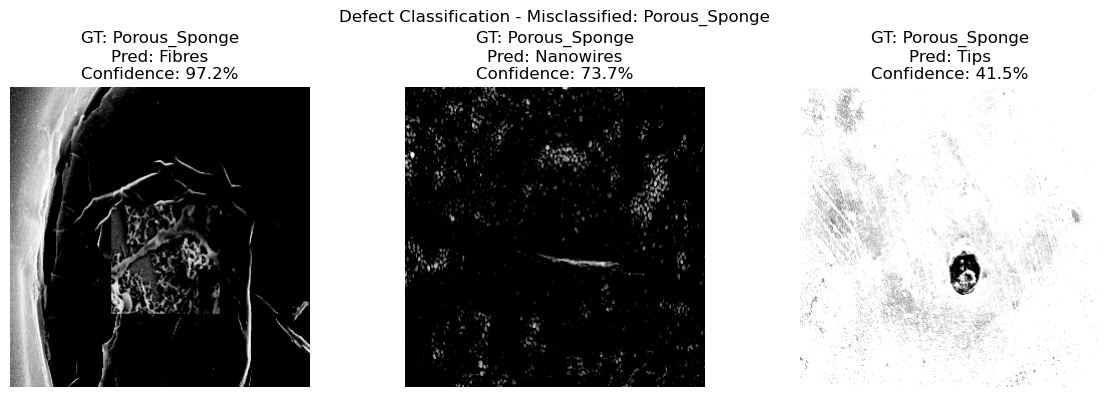

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


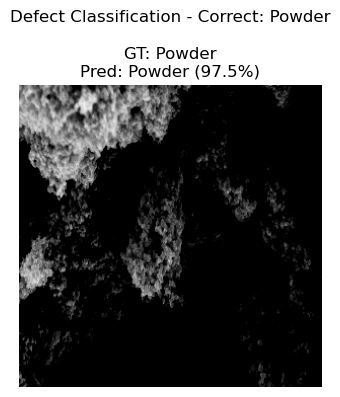

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


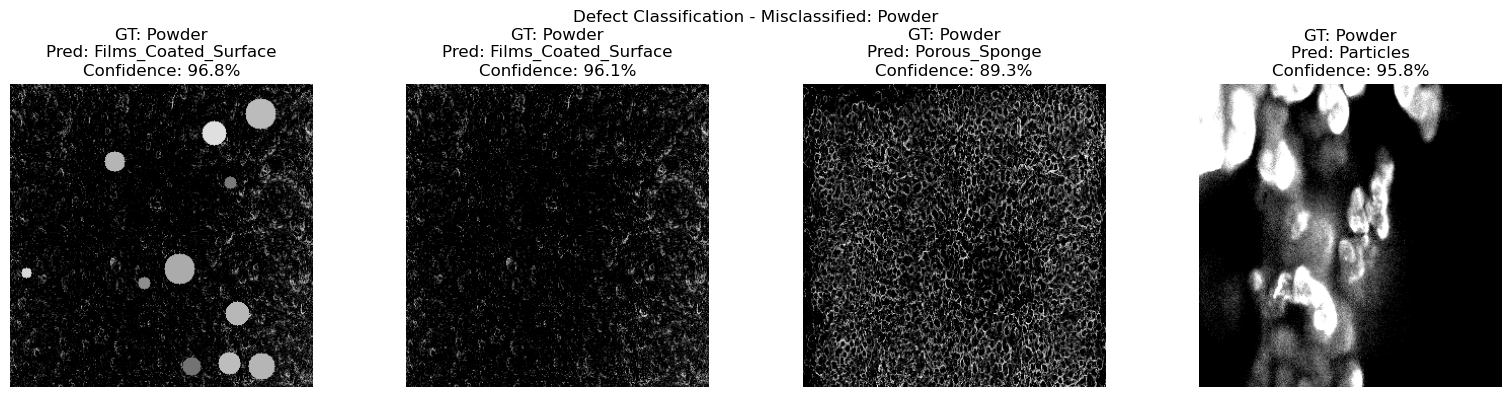

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


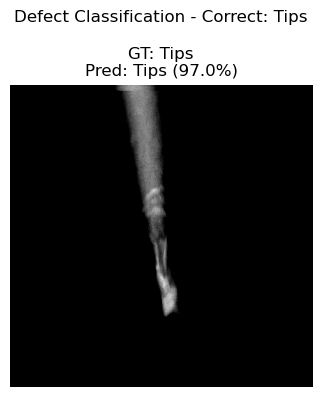

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


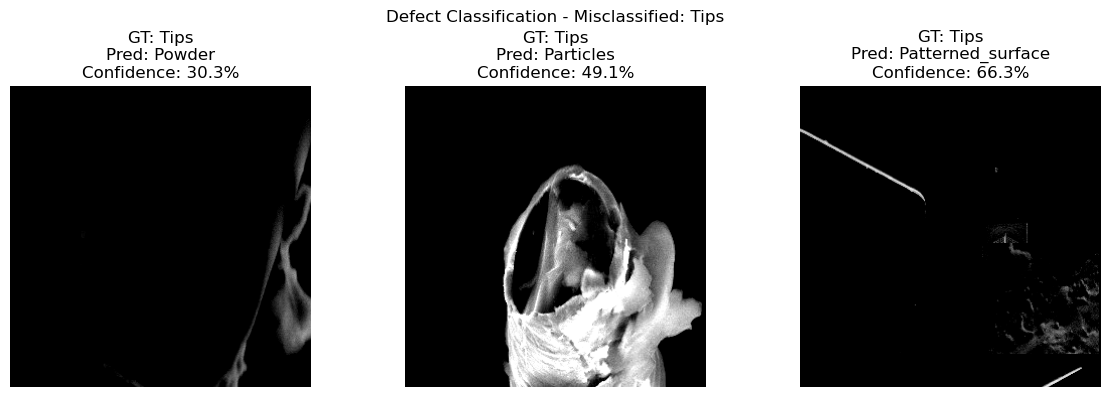

In [30]:
show_classification_examples(
    results["samples"]["defect"],
    DEFECT_NAMES,
    "Defect Classification",
    n_correct=1,
    n_wrong=1,
    random_defect_wrong=True,
    seed=42
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).



Domain Classification


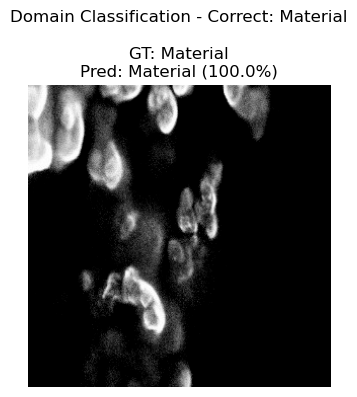

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


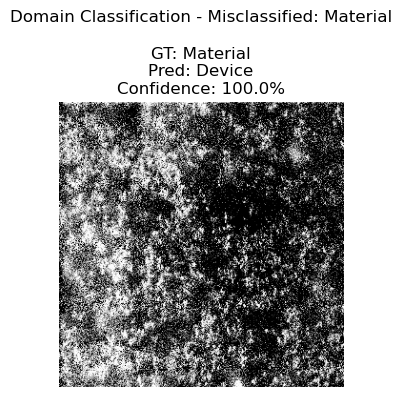

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


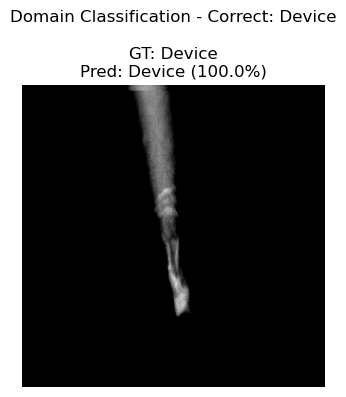

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


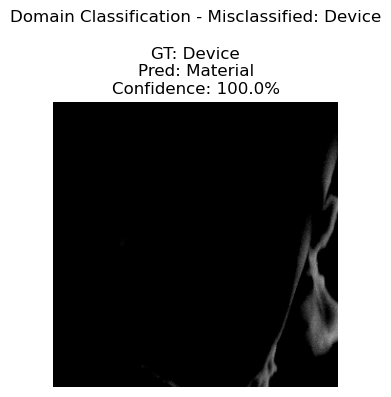

In [31]:
show_classification_examples(
    results["samples"]["domain"],
    DOMAIN_NAMES,
    "Domain Classification",
    n_correct=1,
    n_wrong=1,
    random_defect_wrong=False,
    seed=42
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).



Authenticity Classification


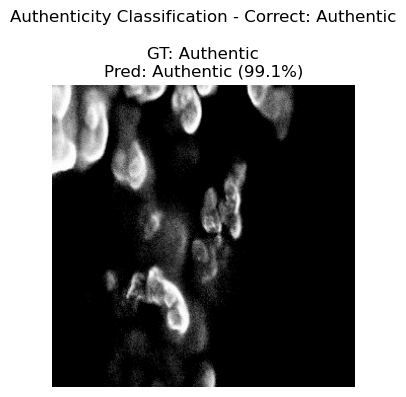

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


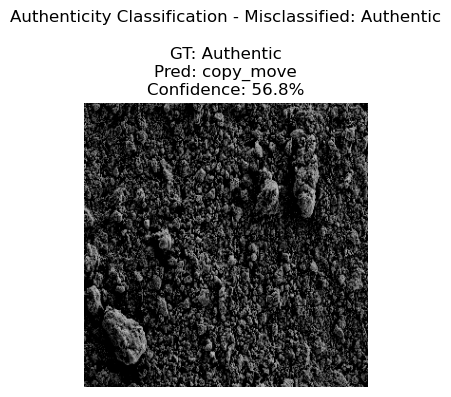

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


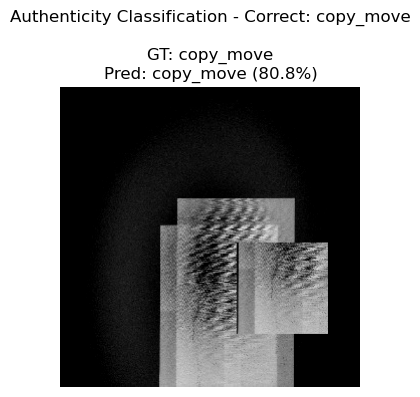

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


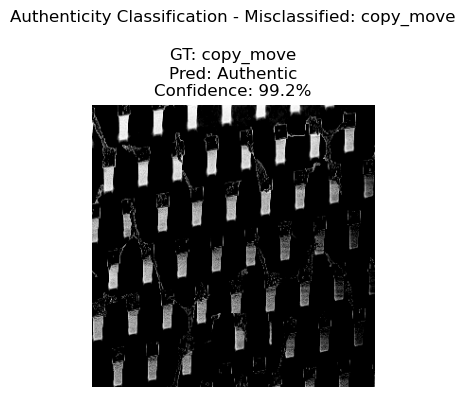

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


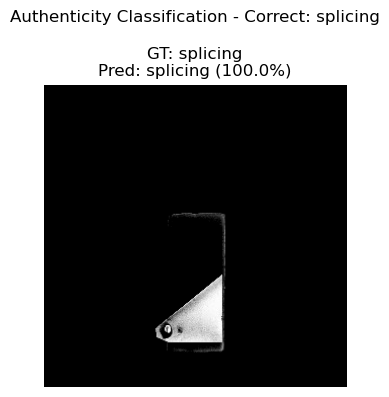

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


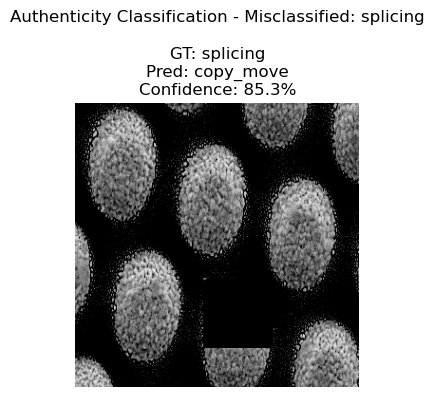

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


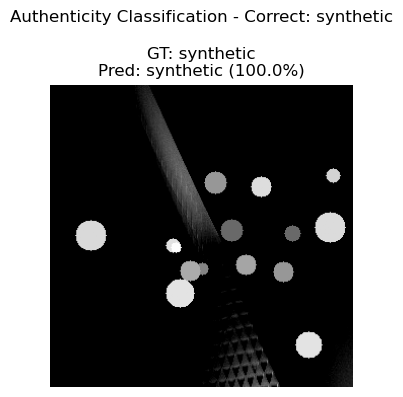

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


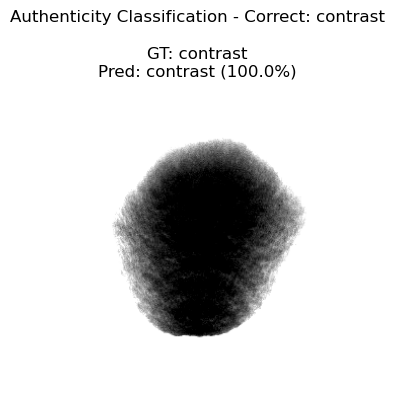

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


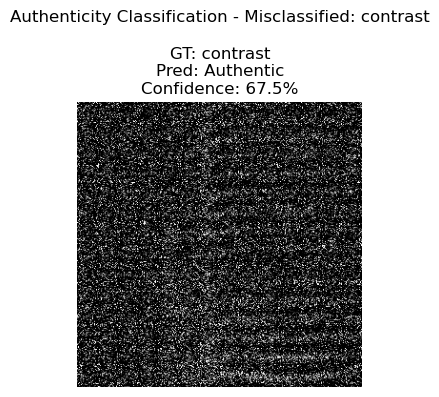

In [32]:
show_classification_examples(
    results["samples"]["auth"],
    AUTH_NAMES,
    "Authenticity Classification",
    n_correct=1,
    n_wrong=1,
    random_defect_wrong=False,
    seed=42
)